# Bivariate data - Basics

This tutorial focuses on working with paired (bivariate) data using `plans`: loading `x`/`y` samples, visualizing their joint distribution and measuring their agreement with standard metrics.

## Notebook setup

For users running this tutorial as a Jupyter Notebook, this cell must be executed first:

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd

# Install `plans` in `google.colab`.
# Use `pip install plans` for other environments.

if "google.colab" in sys.modules:
    import os
    os.system(f"{sys.executable} -m pip install -q plans")

# This avoids warnings related to uninstalled fonts
import logging
# Set the matplotlib font manager logger to only show errors (hides warnings)
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)

# define output folder
OUTPUT_DIR = Path("outputs/bivariate")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"Outputs will be saved to: ./{OUTPUT_DIR}")

Outputs will be saved to: ./outputs\bivariate


## The `Bivar` object

The `Bivar` object lives under the `plans.analyst` module. Like `Univar`, it is a child of the `DataSet` object from `plans.root`, so it shares the same lifecycle: create the object, feed it data, and let `.update()` refresh the derived attributes.

```{seealso}
Check out the {doc}`Univariate data - Basics <univar_01>` tutorial first.
```

Import `Bivar` object:

In [2]:
from plans.analyst import Bivar

Create an instance of the `Bivar`:

In [3]:
bv = Bivar(name="Discharge", alias="Q")

Check out the variable type:

In [4]:
print(type(bv))

<class 'plans.analyst.Bivar'>


## Handle data attributes

Columns are named by `.xfield` and `.yfield`, while `.xname`, `.yname`, `.xunits` and `.yunits` are only used as labels in visuals and metadata. Set labels **before** loading data, so the axis labels are built from them:

In [5]:
bv.description = "Observed and simulated daily discharge for a tutorial"
bv.xname = "Observed"
bv.xunits = "m3/s"
bv.yname = "Simulated"
bv.yunits = "m3/s"
print(f"x column: {bv.xfield} | y column: {bv.yfield}")

x column: x | y column: y


## Working with data

### Create synthetic dataset

A common bivariate case in hydrology is comparing observed against simulated discharge. Lets make one year of skewed daily observations and a simulation that slightly overestimates them with some noise. A couple of values are missing.

In [6]:
# make synthetic data
rng = np.random.default_rng(seed=42)  # ensure reproducibility
q_obs = rng.gamma(shape=2, scale=10, size=365)
q_sim = 1.05 * q_obs + rng.normal(loc=0, scale=3, size=len(q_obs))
q_sim = np.clip(q_sim, a_min=0, a_max=None)
df = pd.DataFrame({"q_obs": q_obs, "q_sim": q_sim})
df.loc[[3, 7], "q_sim"] = np.nan

# Export CSV file
file_csv = OUTPUT_DIR / "bivariate_discharge.csv"
df.to_csv(file_csv, sep=";", index=False)
print(f"Saved to: {file_csv}")
df.head()

Saved to: outputs\bivariate\bivariate_discharge.csv


,q_obs,q_sim
0,20.918173,15.121868
1,28.353456,25.281213
2,18.372156,16.522104
3,16.450704,NaN
4,30.792553,33.179942


### Loading data from the CSV file

Call the `.load_data()` method, pointing which file columns hold `x` and `y`. They are renamed to `.xfield` and `.yfield` on loading:

In [7]:
bv.load_data(
    file_data=file_csv,  # file path
    input_xfield="q_obs",  # name of x column
    input_yfield="q_sim",  # name of y column
    in_sep=";",  # input separator
)

Data is stored in the `.data` attribute as a `pandas.DataFrame`. Incomplete pairs are dropped and rows are sorted by `x`:

In [8]:
bv.data

,x,y
0,0.927625,4.918430
1,1.046498,0.402015
2,1.073776,0.000000
3,1.474360,7.263258
4,1.513774,3.123128
...,...,...
358,68.394419,73.005240
359,70.228886,71.807229
360,71.510124,73.848619
361,74.869975,75.930436


```{tip}
For in-memory arrays, use `.set_data(x=..., y=...)` instead. It applies the same cleaning and sorting.
```

### Access computed attributes

After loading data, some attributes are computed automatically:

In [9]:
print(f"Size: {bv.size}")
print(f"x range: {bv.x_min:.2f} to {bv.x_max:.2f}")
print(f"y range: {bv.y_min:.2f} to {bv.y_max:.2f}")

Size: 363
x range: 0.93 to 89.34
y range: 0.00 to 96.36


Inspect the object metadata:

In [10]:
bv.get_metadata()

{'name': 'Discharge',
 'alias': 'Q',
 'size': 363,
 'color': 'blue',
 'source': None,
 'description': 'Observed and simulated daily discharge for a tutorial',
 'xunits': 'm3/s',
 'yunits': 'm3/s',
 'file_data': 'C:\\Users\\Ipo\\AppData\\Local\\Temp\\claude\\C--Users-Ipo-PycharmProjects-plans\\f8d04d3e-cf5c-442f-b56e-ee185207a61b\\scratchpad\\nbrun\\outputs\\bivariate\\bivariate_discharge.csv'}

## Visualizations

### Standard visualization

Get the standard visual using the `.view()` method. The `full` layout shows the scatter plot with the marginal histograms of `x` (top) and `y` (right):

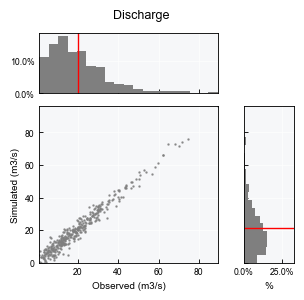

In [11]:
bv.view()

### Fine-tuning visuals

Like other `plans` objects, use the `.view_specs` keys for fine tuning. When comparing the same variable, equal axis ranges make the plot easier to read:

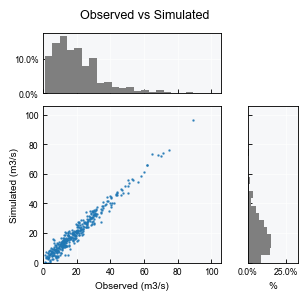

In [12]:
q_max = 1.1 * max(bv.x_max, bv.y_max)
bv.view_specs["range_x"] = [0, q_max]
bv.view_specs["range"] = [0, q_max]
bv.view_specs["color"] = "tab:blue"
bv.view_specs["bins"] = 20  # default None uses the Freedman-Diaconis rule
bv.view_specs["plot_mean"] = False
bv.view_specs["title"] = "Observed vs Simulated"
bv.view()

```{seealso}
The `model` layout for model assessment is covered in the {doc}`Bivariate data - Models <bivar_02_models>` tutorial.
```

## Metrics

All metrics are static methods, so they can be used on any pair of arrays. Correlations are symmetric and take any two variables `x` and `y`:

- **Pearson** $r$ measures *linear* association.
- **Spearman** $\rho$ is the Pearson $r$ of the ranks, so it measures *monotonic* association. It reaches 1 for any increasing relation, linear or not.

Agreement metrics are not symmetric and take an `observed` and a `predicted` series of the same variable:

- **Coefficient of determination** $R^2 = 1 - SS_{res} / SS_{tot}$ is the fraction of observed variance explained by the predictions. It is negative when the predictions are worse than the observed mean.
- **RMSE**, **MAE** and **Bias** (%) measure the error magnitude and its direction. Bias is positive when the predictions overestimate.

In [13]:
obs = bv.data[bv.xfield].values
sim = bv.data[bv.yfield].values

print(f"r: {Bivar.pearson(x=obs, y=sim):.3f}")
print(f"rho: {Bivar.spearman(x=obs, y=sim):.3f}")
print(f"R2: {Bivar.rsq(observed=obs, predicted=sim):.3f}")
print(f"RMSE: {Bivar.rmse(observed=obs, predicted=sim):.3f}")
print(f"MAE: {Bivar.mae(observed=obs, predicted=sim):.3f}")
print(f"Bias (%): {Bivar.bias(observed=obs, predicted=sim):.3f}")

r: 0.981


rho: 0.963
R2: 0.951
RMSE: 3.138
MAE: 2.506
Bias (%): 5.187


Or get them all at once with `Bivar.get_metrics()`:

In [14]:
Bivar.get_metrics(observed=obs, predicted=sim)

{'r': 0.9806092604096892,
 'rho': 0.9631908543435195,
 'R2': 0.9511562724941502,
 'RMSE': 3.138448669315695,
 'MAE': 2.5062203403528738,
 'Bias': 5.187163628629581}

### Association versus agreement

To see how metrics differ, compare our simulation with two noiseless but distorted ones: a *doubled* series ($2 \cdot obs$) and a *curved* series, still increasing but no longer a straight line:

In [15]:
sim_doubled = 2 * obs
sim_curved = 20 * np.power(obs / 20, 1.5)

df_metrics = pd.DataFrame(
    {
        "simulated": Bivar.get_metrics(observed=obs, predicted=sim),
        "doubled": Bivar.get_metrics(observed=obs, predicted=sim_doubled),
        "curved": Bivar.get_metrics(observed=obs, predicted=sim_curved),
    }
).T
df_metrics

,r,rho,R2,RMSE,MAE,Bias
simulated,0.980609,0.963191,0.951156,3.138449,2.506220,5.187164
doubled,1.000000,1.000000,-1.980150,24.514875,19.982952,100.000000
curved,0.980011,1.000000,0.216667,12.568511,6.040198,17.567995


Both distortions keep the ranks, so $\rho = 1$. The doubled series is still a straight line, so $r = 1$ as well, and the curved one stays close to it. Yet both have a much lower $R^2$ than the noisy simulation: correlations measure *association* (how well some line or curve relates the series), while $R^2$ and the error metrics measure *agreement* with the 1:1 line.